# 03 — Séries temporais, anomalias e ROI

**Objetivo.** (1) Entender a relação física vazão × velocidade × largura × taxa; (2) detectar desvios com **regras explicáveis** e comparar com **IsolationForest**; (3) medir detecção contra a verdade do simulador e a taxa de falso alarme; (4) calcular ROI com **premissas explícitas** e análise de sensibilidade.

> ⚠️ **Dados SIMULADOS e ROI ILUSTRATIVO.** Detecção medida sobre falhas que *nós* injetamos, com regras escritas conhecendo o simulador: o resultado é otimista por construção e **não** é desempenho em campo. O cenário de ROI usa números fictícios — não são preços nem benchmarks de mercado.

**Regras de honestidade que o código impõe:** alertas são informativos (nenhum comando é gerado); uma regra só roda se o sensor existe; a pressão é **global** — o sistema não diagnostica bico, filtro ou mangueira.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from agrofleet.simulator.fleet import simulate
from agrofleet.analytics.frame import to_frame
from agrofleet.analytics import anomalies as A
from agrofleet.analytics import roi as R
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pts, truth = simulate(seed=7); df = to_frame(pts)
ev = pd.DataFrame(truth.events)
print(len(df), "amostras SIMULADAS")

11331 amostras SIMULADAS


## 1. A relação física que sustenta a regra de vazão

Para aplicar $q$ L/ha a velocidade $v$ (km/h) com barra de largura $w$ (m): cada hora a máquina cobre $v\,w/10$ ha, logo o volume por hora é $q\,v\,w/10$ L/h, ou em L/min:

$$Q_{esp} = \frac{q \cdot v_{km/h} \cdot w}{600}.$$

Exemplo: $100 \times 18 \times 24/600 = 72$ L/min. Em uma máquina com **controlador de taxa**, $Q$ acompanha $v$ (quando a velocidade cai, a vazão cai para manter L/ha). Portanto o desvio relevante **não é "vazão baixa"**, e sim *vazão diferente da esperada para aquela velocidade, largura e taxa reportadas*.

**Por quê assim?** Um limite fixo de vazão (ex.: "alerta abaixo de 60 L/min") dispararia em toda parada e manobra e deixaria passar uma falha em velocidade alta. A relação física normaliza isso.

**Alternativa:** modelo estatístico puro (z-score da vazão). Funciona sem conhecer taxa/largura, mas confunde mudança de velocidade com falha e exige histórico limpo.

**Como verificar:** a dispersão vazão × velocidade em trabalho deve ser uma reta pela origem com inclinação $q\cdot3{,}6\cdot w/600$ ($=14{,}4$ L/min por m/s).

inclinação ajustada: 14.40 L/min por m/s | teórica: 14.40


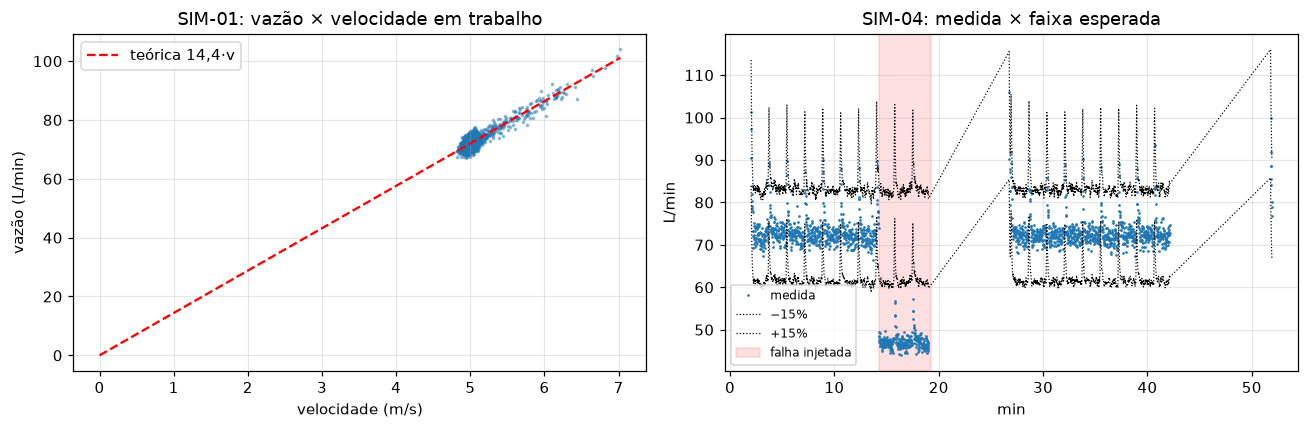

In [2]:
g = df[(df.machine_id == "SIM-01") & (df.state == "working") & (df.speed_ms > 0.5)]
slope, = np.linalg.lstsq(g.speed_ms.to_numpy()[:, None], g.flow_lpm.to_numpy(), rcond=None)[0]
print(f"inclinação ajustada: {slope:.2f} L/min por m/s | teórica: {100*3.6*24/600:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(g.speed_ms, g.flow_lpm, s=2, alpha=.4); xs = np.linspace(0, g.speed_ms.max(), 10); ax[0].plot(xs, 14.4 * xs, "r--", label="teórica 14,4·v")
ax[0].set_xlabel("velocidade (m/s)"); ax[0].set_ylabel("vazão (L/min)"); ax[0].set_title("SIM-01: vazão × velocidade em trabalho"); ax[0].legend()
h = df[df.machine_id == "SIM-04"].copy(); h["min"] = (h.ts - h.ts.min()).dt.total_seconds() / 60
w = h[h.state == "working"].copy()
w["esp"] = w.application_rate_lha * w.speed_ms * 3.6 * w.working_width_m / 600
ax[1].plot(w["min"], w.flow_lpm, ".", ms=1.5, label="medida"); ax[1].plot(w["min"], w.esp * 0.85, "k:", lw=.8, label="−15%"); ax[1].plot(w["min"], w.esp * 1.15, "k:", lw=.8, label="+15%")
for _, e in ev[ev.machine_id == "SIM-04"].iterrows():
    t0, t1 = [(pd.Timestamp(e[k]) - h.ts.min()).total_seconds() / 60 for k in ("start", "end")]; ax[1].axvspan(t0, t1, color="red", alpha=.12, label="falha injetada")
ax[1].set_xlabel("min"); ax[1].set_ylabel("L/min"); ax[1].set_title("SIM-04: medida × faixa esperada"); ax[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Como ler.** *Esquerda:* a nuvem fica sobre a reta teórica; a inclinação ajustada (14,40 L/min por m/s) coincide com a teórica. **Ressalva:** o simulador só trabalha entre ~4,8 e ~7 m/s, então a reta "pela origem" está verificada apenas nessa faixa — a extrapolação até velocidade zero é a teoria, não dado. A dispersão vertical (~±3 L/min) é o ruído de 2% do simulador somado à variação de velocidade; os pontos de 6–7 m/s são as entradas nas passadas (a máquina chega rápido e desacelera).

*Direita (SIM-04):* os pontos azuis ficam dentro da faixa ±15% — que **oscila** porque o "esperado" acompanha a velocidade — e, na janela vermelha, caem para ~47 L/min, bem abaixo do limite inferior (~61 L/min). Os picos de entrada de passada ficam *dentro* da faixa móvel, por isso não geram alarme; um limite fixo (por exemplo 80 L/min) os acusaria como falha. As linhas pontilhadas retas entre trechos são só o `plot` ligando pontos através dos intervalos fora de trabalho (reabastecimento).

## 2. Regras explicáveis × verdade injetada

**O quê.** `detect()` aplica regras por máquina: desvio de vazão, pressão fora de faixa/atípica, velocidade, parada em trabalho, falha reportada, perda/degradação de GNSS, lacuna de dados, sensor sem dado ou travado. Um evento só vira alerta se for **sustentado** (≥ 20 s por padrão), para não alarmar com ruído de uma amostra.

**Por quê regras primeiro.** São auditáveis: cada alerta carrega a regra e a evidência (`median_deviation_pct`, `n_samples`...). Quem recebe sabe *por que* foi avisado.

**Como verificar.** Comparamos com a verdade: um evento injetado conta como detectado se algum alerta de tipo compatível se sobrepõe a ele (tolerância de 30 s). Alertas sem evento correspondente são listados — não escondidos.

In [3]:
res = A.detect(df)
tab = pd.DataFrame([a.to_dict() for a in res.alerts])[["machine_id", "type", "start", "duration_s", "severity", "rule"]]
tab["start"] = tab.start.str[11:19]
print(tab.to_string(index=False))
print("\nregras puladas (sensor ausente):", res.skipped_rules)
E = A.evaluate(res.alerts, truth.events)
print("\nrecall nos eventos injetados:", E["recall"])
for e in E["events"]: print(f"  {e['machine_id']} {e['type']:14s} detectado={e['detected']} por={e['by']} atraso_s={e['delay_s']}")
print("alertas sem evento correspondente:", E["unmatched_alerts"])

machine_id              type    start  duration_s severity                                   rule
    SIM-03    sensor_missing 10:03:24        89.0  warning          null while working [flow_lpm]
    SIM-03    sensor_missing 10:03:24        89.0  warning      null while working [pressure_bar]
    SIM-03    sensor_missing 10:04:59        54.0  warning          null while working [flow_lpm]
    SIM-03    sensor_missing 10:04:59        54.0  warning      null while working [pressure_bar]
    SIM-03         gnss_loss 10:08:30       239.0  warning                no position | fix==none
    SIM-02        fault_stop 10:10:30       419.0  warning             state==fault | error_codes
    SIM-03 gnss_accuracy_low 10:12:30       119.0     info                        accuracy>limite
    SIM-03     gnss_degraded 10:12:30       119.0     info                          fix!=expected
    SIM-04    flow_deviation 10:14:15        87.0  warning flow_vs_expected(rate*speed*width/600)
    SIM-04  pressure

**Como ler.**
- **Recall 4/4 e atraso 0 s** são otimistas por construção: as regras foram escritas conhecendo o simulador. Além disso, `evaluate` aceita `pressure_outlier` como detecção de `abnormal_flow` (mapa `ACCEPT`): com tolerância de vazão de 45% a regra de vazão não dispara, mas o evento ainda conta como detectado pela pressão (verificado; ver `docs/GUIA_TECNICO.md`, seção 7.6). Para medir a regra de vazão sozinha, passe só os alertas `flow_deviation` ao `evaluate`. O "atraso 0 s" mede o *início* do alerta (primeira amostra da sequência); o alerta só pode ser **emitido** depois de `min_duration_s` (20 s), então a latência operacional é ≥ 20 s.
- **Um evento ≠ um alerta.** A falha de vazão do SIM-04 gerou **3** alertas `flow_deviation` (e 3 `pressure_outlier`): a regra só considera amostras em `working`, e entre passadas a máquina está em deslocamento, o que parte a sequência. Da mesma forma `sensor_missing` aparece em 4 linhas: 2 sensores (vazão e pressão; veja a coluna `rule`) × 2 trechos de trabalho. Contar alertas como se fossem eventos superestima.
- **`pressure_outlier` dispara junto com a vazão** porque, no nosso simulador, a pressão é modelada como função da vazão. Em máquina real a resposta da pressão a uma restrição depende da bomba e da válvula de controle (pode subir ou cair). Essa coincidência é propriedade do simulador, não evidência sobre pressão real — e por isso a mensagem diz que a pressão é **global** e não aponta bico.
- **Os 2 alertas "sem evento correspondente"** (`gnss_accuracy_low` e `gnss_degraded`, 10:12:30–10:14:29) são a reconvergência RTK-float de 2 min após a perda de GNSS: consequência legítima, mas não injetamos como evento separado, então a avaliação os lista como não correspondidos em vez de escondê-los.
- `regras puladas: []`: todos os sensores existem neste conjunto; no teste automatizado removemos vazão/pressão e as regras correspondentes são puladas com o motivo.

## 3. Sensibilidade ao limiar de vazão, com sensor ruidoso

Com o ruído de 2% do simulador qualquer tolerância razoável separa bem a falha (−35%) do normal. Isso é **fácil demais** para ser informativo. Vamos degradar: multiplicamos a vazão de todas as máquinas por ruído lognormal de σ=8% (um fluxômetro ruim) e varremos `flow_tol_pct`.

**Métricas.** Por *amostra*: dentre as amostras em trabalho, quantas ficam em alerta `flow_deviation` (a) dentro da janela injetada (verdadeiros positivos, TP) e (b) fora dela (falsos positivos, FP). Reportamos recall = TP / amostras na janela e FP por hora de trabalho.

 tol_pct  min_dur_s  alertas  recall_amostras  FP_amostras  FP_por_h_trabalho
       5         10      182            1.000         4453           2213.587
       5         20       99            1.000         3213           1597.183
      10         10       23            1.000          267            132.726
      10         20        3            1.000           10              4.971
      15         10        3            1.000            0              0.000
      15         20        3            1.000            0              0.000
      20         10        3            1.000            0              0.000
      20         20        3            1.000            0              0.000
      25         10        3            1.000            0              0.000
      25         20        3            1.000            0              0.000
      35         10        8            0.520            0              0.000
      35         20        2            0.161            0      

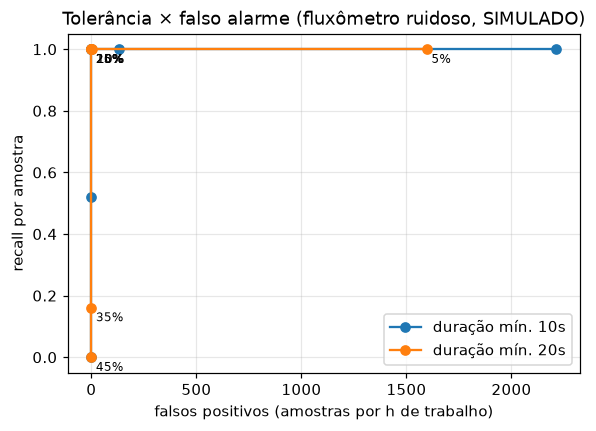

In [4]:
rng = np.random.default_rng(1)
noisy = df.copy(); noisy["flow_lpm"] = noisy.flow_lpm * np.exp(rng.normal(0, 0.08, len(noisy)))
win = ev[ev.type == "abnormal_flow"].iloc[0]; w0, w1 = pd.Timestamp(win.start), pd.Timestamp(win.end)
rows = []
for tol in (5, 10, 15, 20, 25, 35, 45):
    for dur in (10, 20):
        cfg = A.AnomalyConfig(flow_tol_pct=tol, min_duration_s=dur, use_iforest=False)
        r = A.detect(noisy, cfg); fl = [a for a in r.alerts if a.type == "flow_deviation"]
        tp = fp = 0
        for a in fl:
            m = noisy[(noisy.machine_id == a.machine_id) & (noisy.ts >= a.start) & (noisy.ts <= a.end)]
            inw = (m.machine_id == "SIM-04") & (m.ts >= w0) & (m.ts <= w1)
            tp += int(inw.sum()); fp += int((~inw).sum())
        work_h = (noisy.state == "working").sum() / 3600
        nin = int(((noisy.machine_id == "SIM-04") & (noisy.ts >= w0) & (noisy.ts <= w1) & (noisy.state == "working")).sum())
        rows.append(dict(tol_pct=tol, min_dur_s=dur, alertas=len(fl), recall_amostras=tp / nin, FP_amostras=fp, FP_por_h_trabalho=fp / work_h))
S = pd.DataFrame(rows); print(S.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 4))
for d, gg in S.groupby("min_dur_s"): ax.plot(gg.FP_por_h_trabalho, gg.recall_amostras, "o-", label=f"duração mín. {d}s")
for _, r in S[S.min_dur_s == 20].iterrows(): ax.annotate(f"{int(r.tol_pct)}%", (r.FP_por_h_trabalho, r.recall_amostras), fontsize=8, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("falsos positivos (amostras por h de trabalho)"); ax.set_ylabel("recall por amostra"); ax.set_title("Tolerância × falso alarme (fluxômetro ruidoso, SIMULADO)"); ax.legend()
plt.show()

**Como ler.** Com fluxômetro ruidoso (σ=8%), a **tolerância** é o parâmetro decisivo:
- **5%:** milhares de falsos positivos (~1 600–2 200 amostras por hora de trabalho): o limite está dentro do ruído.
- **10%:** 133 FP/h com persistência de 10 s, mas só ~5 FP/h com 20 s — exigir persistência maior compra redução de falso alarme ao custo de latência.
- **15–25%:** zero FP e recall por amostra 1,0 — a faixa útil aqui (acima de ~2σ do ruído e e abaixo da queda de vazão da falha (de ~72 para ~47 L/min, algo como −35% nas passadas típicas; valor aproximado lido da figura)).
- **35%:** recall cai para 0,52 (10 s) e 0,16 (20 s): o limite encostou na magnitude da falha, metade das amostras caem dentro e a persistência é interrompida. **45%:** não detecta nada.

Moral: o limiar tem de ficar entre ~2σ do ruído do **seu** sensor e a menor falha que você quer enxergar. Estes números dependem do ruído simulado; não copie `15%` para uma máquina real sem medir o ruído do fluxômetro dela.

## 4. IsolationForest: o parâmetro `contamination` é um *orçamento de alarmes*

**O quê.** `IsolationForest` não supervisionado sobre `[L/ha realizado, pressão, velocidade]` das amostras em trabalho, por máquina. `contamination=c` manda marcar **exatamente** a fração `c` mais atípica como anomalia.

**Por quê o risco.** Se a máquina está perfeitamente normal, ainda assim uma fração `c` será marcada. Ou seja: em dados limpos, tudo o que o modelo alerta é falso positivo por construção. Ele só é útil se `c` for ≈ à proporção real de anomalias — que ninguém conhece de antemão.

**Como verificar.** Varremos `c` e contamos alertas ML em cada máquina; SIM-01 é limpa (qualquer alerta ML ali é falso), SIM-04 tem a falha de vazão.

In [5]:
rows = []
for c in (0.01, 0.02, 0.05, 0.10, 0.15):
    r = A.detect(df, A.AnomalyConfig(iforest_contamination=c))
    ml = [a for a in r.alerts if a.type == "ml_multivariate_outlier"]
    ev_ = A.evaluate(ml, [e for e in truth.events if e["type"] == "abnormal_flow"])
    rows.append(dict(contamination=c, **{m: sum(a.machine_id == m for a in ml) for m in ["SIM-01", "SIM-02", "SIM-03", "SIM-04"]},
                     detectou_falha_vazao=ev_["recall"] == 1.0, alertas_ML_totais=len(ml)))
I = pd.DataFrame(rows); print(I.to_string(index=False))
print("\nregra de vazão (referência), sem ML:", sum(a.type == "flow_deviation" for a in A.detect(df, A.AnomalyConfig(use_iforest=False)).alerts), "alertas, todos no SIM-04")

 contamination  SIM-01  SIM-02  SIM-03  SIM-04  detectou_falha_vazao  alertas_ML_totais
          0.01       0       0       0       0                 False                  0
          0.02       0       0       0       0                 False                  0
          0.05       0       0       1       1                  True                  2
          0.10       2       6       3       3                  True                 14
          0.15       9      12       7       2                  True                 30

regra de vazão (referência), sem ML: 3 alertas, todos no SIM-04


**Como ler.** O `IsolationForest` mostra o problema do orçamento de alarmes:
- Com `contamination` 0,01 e 0,02 ele **não detecta** a falha (os poucos pontos marcados são picos isolados de entrada de passada, que não formam sequência sustentada).
- Com 0,05 detecta a falha no SIM-04, mas já gera 1 alerta numa máquina sem falha de vazão (SIM-03).
- Com 0,10 e 0,15 aparecem alertas em **todas** as máquinas, inclusive na SIM-01 (limpa): 2 e 9 alertas, todos falsos por construção; no total 14 e 30 alertas para uma única falha real.

A regra física (3 alertas, todos no SIM-04) é mais precisa **neste** cenário porque conhecemos a relação física e há taxa/largura reportadas. O IsolationForest só se justifica onde não há modelo físico simples (ex.: combinações de sensores sem relação conhecida), com `contamination` calibrado em dados rotulados — e ainda assim deve alimentar triagem humana, não decisão automática. No streaming do backend o ML fica **desligado** (só regras); ele roda sob demanda.

## 5. ROI: premissas explícitas e sensibilidade

**Modelo** (todas as premissas são parâmetros; nenhuma é "dado de mercado"):

- custo fixo anual/máquina $=\dfrac{C-V}{N} + j\,\dfrac{C+V}{2} + m\,C$ (depreciação linear + juros sobre capital médio + manutenção), com capex $C$, residual $V$, vida $N$;
- horas/ano $= \dfrac{\text{área}\times\text{aplicações}}{\text{produtividade autônoma (ha/h)}}$;
- custo autônomo/ha $= \dfrac{n\,\text{fixo} + (\text{energia}+\text{supervisão})\times\text{horas}}{\text{área tratada}} + p\,(1+\text{sobreposição}_{aut})$;
- custo convencional/ha $= \dfrac{\text{custo horário}}{\text{produtividade}_{conv}} + p\,(1+\text{sobreposição}_{conv})$;
- benefício líquido/ano $=(\text{conv}-\text{aut})\times\text{área tratada}$; payback $=\text{capex total}/\text{benefício}$ (indefinido se ≤ 0); VPL descontado na vida útil.

**Por quê.** O valor de uma máquina autônoma costuma ser vendido por três fontes: menos insumo (sobreposição), mais produtividade (ha/h) e menos mão de obra. O modelo separa cada uma e deixa explícito qual premissa move o resultado — a **sensibilidade** responde "o que eu preciso saber melhor antes de decidir?".

**Limites.** Não inclui impostos, financiamento, custo de falha/parada, ganho agronômico (produtividade da cultura, janela de aplicação) nem risco regulatório. O cenário abaixo é **ilustrativo**.

é exemplo: True
custo/ha autônoma 118.1 | convencional 115.2 | benefício/ano -105,600 | payback None | VPL -3,827,483
horas/ano totais: 1200.0 | por máquina: 300.0
                      premissa  valor  beneficio_menos20  beneficio_mais20  variacao
             capex_per_machine 900000            45600.0         -256800.0  302400.0
                    n_machines      4            45600.0         -256800.0  302400.0
baseline_productivity_ha_per_h     25            56400.0         -213600.0  270000.0
              area_ha_per_year   6000          -235680.0           24480.0  260160.0
         applications_per_year      6          -235680.0           24480.0  260160.0
          baseline_hourly_cost    450          -235200.0           24000.0  259200.0
             useful_life_years      8          -195600.0          -45600.0  150000.0
          baseline_overlap_pct      8          -157440.0          -53760.0  103680.0

pontos de equilíbrio (benefício = 0): {'area_ha_per_year': 6974.17, 'a

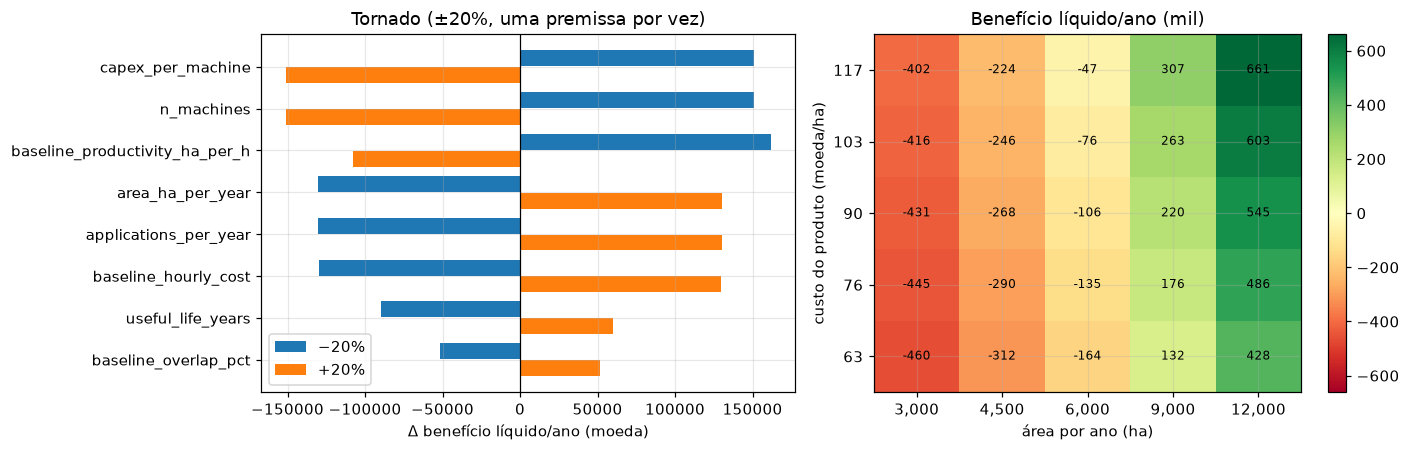

In [6]:
I0 = R.EXAMPLE_INPUTS
r = R.compute(I0)
print("é exemplo:", r["is_example"])
print(f"custo/ha autônoma {r['autonomous']['total_cost_per_ha']:.1f} | convencional {r['baseline']['total_cost_per_ha']:.1f} | benefício/ano {r['net_benefit_per_year']:,.0f} | payback {r['payback_years']} | VPL {r['npv_over_useful_life']:,.0f}")
print("horas/ano totais:", r["machine_hours_per_year"], "| por máquina:", r["hours_per_machine_per_year"])
sens = R.sensitivity(I0, 20)
T = pd.DataFrame([dict(premissa=t["input"], valor=t["value"], beneficio_menos20=t["low"]["net_benefit_per_year"], beneficio_mais20=t["high"]["net_benefit_per_year"], variacao=t["swing_net_benefit"]) for t in sens["tornado"]])
print(T.head(8).round(0).to_string(index=False))
be = {n: R.break_even(I0, n, getattr(I0, n) * .05, getattr(I0, n) * 10) for n in ("area_ha_per_year", "auto_productivity_ha_per_h", "capex_per_machine", "product_cost_per_ha", "baseline_overlap_pct")}
print("\npontos de equilíbrio (benefício = 0):", {k: (round(v, 2) if v else v) for k, v in be.items()})
top = sens["tornado"][:8]; base = sens["base_net_benefit_per_year"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
y = np.arange(len(top))[::-1]
ax[0].barh(y + .2, [t["low"]["net_benefit_per_year"] - base for t in top], .38, label="−20%", color="tab:blue")
ax[0].barh(y - .2, [t["high"]["net_benefit_per_year"] - base for t in top], .38, label="+20%", color="tab:orange")
ax[0].set_yticks(y, [t["input"] for t in top]); ax[0].axvline(0, color="k", lw=.8); ax[0].set_xlabel("Δ benefício líquido/ano (moeda)"); ax[0].set_title("Tornado (±20%, uma premissa por vez)"); ax[0].legend()
xs = [I0.area_ha_per_year * f for f in (.5, .75, 1, 1.5, 2)]; ys = [I0.product_cost_per_ha * f for f in (.7, .85, 1, 1.15, 1.3)]
Z = np.array(R.grid(I0, "area_ha_per_year", "product_cost_per_ha", xs, ys)["net_benefit_per_year"], float)
im = ax[1].imshow(Z / 1e3, origin="lower", cmap="RdYlGn", vmin=-np.abs(Z).max() / 1e3, vmax=np.abs(Z).max() / 1e3, aspect="auto")
ax[1].set_xticks(range(5), [f"{x:,.0f}" for x in xs]); ax[1].set_yticks(range(5), [f"{y:.0f}" for y in ys]); ax[1].set_xlabel("área por ano (ha)"); ax[1].set_ylabel("custo do produto (moeda/ha)")
for i in range(5):
    for j in range(5): ax[1].text(j, i, f"{Z[i, j]/1e3:,.0f}", ha="center", va="center", fontsize=8)
ax[1].set_title("Benefício líquido/ano (mil)"); plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

**Como ler.** No cenário **ilustrativo**, o investimento **não se paga**: custo por ha autônoma 118,1 contra 115,2 convencional, benefício líquido −105 600/ano, sem payback e VPL ≈ −3,8 milhões. Isso é uma consequência dos números fictícios, não uma conclusão sobre autonomia.

Leitura dos resultados:
- **Tornado:** as premissas que mais mexem no resultado são o capex (e o nº de máquinas, que escala o mesmo capex total), a produtividade e o custo horário da operação convencional, e a área por ano (`area_ha_per_year` e `applications_per_year` têm efeito idêntico porque só entram pelo produto, a área tratada). Sobreposição pesa menos que utilização e capex.
- **Pontos de equilíbrio (um fator por vez):** o benefício zera com área ≈ 6 974 ha/ano (+16% sobre 6 000), capex ≈ 774 mil por máquina (−14%), custo do produto ≈ 139/ha (+54%) ou sobreposição convencional ≈ 11,3% (contra 8%). Já a produtividade autônoma precisaria ir a ~67 ha/h (2,2×): **não é a alavanca**. Ou seja: o resultado depende sobretudo de *utilização da frota* e *preço da máquina*.
- **Grade área × produto:** o benefício cresce com os dois eixos. Cresce com o preço do produto *porque o cenário assume que a autônoma repete menos área* (2% contra 8%) e o insumo evitado vale mais quando o produto é caro. Essa dependência é uma premissa, não um fato.

In [7]:
# O que muda se usarmos a produtividade e a sobreposição MEDIDAS na telemetria (aqui, SIMULADA)?
import copy
from agrofleet.analytics.metrics import machine_metrics
ms = [machine_metrics(g) for _, g in df.groupby("machine_id")]
prod = np.mean([m["productivity"]["unique_ha_per_working_h"] for m in ms]); ovl = np.mean([m["coverage"]["overlap_pct_of_gross"] for m in ms])
I1 = copy.deepcopy(I0); I1.auto_productivity_ha_per_h = float(prod); I1.auto_overlap_pct = float(ovl)
I1.provenance = {**I0.provenance, "auto_productivity_ha_per_h": {"source": "measured_telemetry", "origin": ["simulated"]}, "auto_overlap_pct": {"source": "measured_telemetry", "origin": ["simulated"]}}
r1 = R.compute(I1)
print(f"produtividade medida (simulada): {prod:.1f} ha/h (premissa do exemplo: {I0.auto_productivity_ha_per_h})")
print(f"sobreposição medida (simulada): {ovl:.2f}% (premissa do exemplo: {I0.auto_overlap_pct}%; convencional assumida: {I0.baseline_overlap_pct}%)")
print(f"benefício/ano: exemplo {r['net_benefit_per_year']:,.0f} -> com medidos {r1['net_benefit_per_year']:,.0f}; payback {r1['payback_years']}")
print("proveniência:", {k: v for k, v in r1["provenance"].items() if v["source"] == "measured_telemetry"})

produtividade medida (simulada): 39.2 ha/h (premissa do exemplo: 30)
sobreposição medida (simulada): 5.40% (premissa do exemplo: 2%; convencional assumida: 8%)
benefício/ano: exemplo -105,600 -> com medidos -170,878; payback None
proveniência: {'auto_productivity_ha_per_h': {'source': 'measured_telemetry', 'origin': ['simulated']}, 'auto_overlap_pct': {'source': 'measured_telemetry', 'origin': ['simulated']}}


**Como ler.** A telemetria simulada produz 39,2 ha/h e 5,4% de sobreposição (média das 4 máquinas; não separamos aqui o efeito de ruído de posição e de perda de GNSS por máquina), contra 30 ha/h e 2% assumidos no exemplo. O benefício **piora** (−170 878 contra −105 600) porque a sobreposição medida (5,4%) é maior que a assumida (2%), e o ganho de produtividade, isoladamente, não compensa a perda por sobreposição neste cenário.

**Atenção:** esses números medem o **simulador que nós configuramos** (espaçamento de 22–24 m para barra de 24 m), não uma máquina real; não são evidência a favor nem contra a autonomia. O ponto é o encadeamento: o valor medido substitui a premissa e a proveniência (`measured_telemetry`, origem `simulated`) é carregada até o resultado, para que ninguém confunda dado simulado com medição real.

## Referências
Veja `docs/GUIA_TECNICO.md` (seções 7, 8 e 10: metodologia, validação e limitações).